In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

In [2]:
x0_npy = np.load("../data/trajectories_npy/test01/G1_to_S/x0.npy")

points = x0_npy[0, :].reshape((int(x0_npy.shape[1]/3), 3))

In [3]:
def get_chrom_sizes(resolution, chrom_sizes_path="../chrom_sizes/mm10.txt"):
    """
    Returns a tuple with a list of chromosome sizes in basepairs and list of chromosome sizes in beads.
    Order of chroms is as follows: chr1, chr2, ..., chr19, chrX.
    """
    chroms = ["chr"+str(i) for i in range(1, 20)] + ["chrX"]
    chrom_sizes = [int(pd.read_csv(chrom_sizes_path, header=None, index_col=0, sep="\t").loc[chrom.split("-")[0], 1]) \
                   for chrom in chroms]
    ms = [int(np.ceil(chrom_size/resolution)) for chrom_size in chrom_sizes]
    return chrom_sizes, ms

In [4]:
def visualize_single_chrom(points):
    """
    Interactive plotly visualization of a single chromosome in the form of (m,3) np.array.
    Consecutive points (rows in points array) are assumed to be connected).
    """
    n = points.shape[0]
    # edge_indices = np.vstack([[i, i+1] for i in range(n-1)])

    ms = [98]
    k = 0
    edge_indices = []
    for i in range(len(ms)):
        for _ in range(2):
            for j in range(ms[i]):
                if j != ms[i]-1:
                    edge_indices.append([k, k+1])
                k += 1
    
    edge_indices = np.vstack(edge_indices)
    
    # Construct x, y, z coordinates for lines separated by None
    edge_x, edge_y, edge_z = [], [], []
    for start_idx, end_idx in edge_indices:
        edge_x.extend([points[start_idx, 0], points[end_idx, 0], None])
        edge_y.extend([points[start_idx, 1], points[end_idx, 1], None])
        edge_z.extend([points[start_idx, 2], points[end_idx, 2], None])
    
    # 3. Create interactive WebGL traces
    scatter_trace = go.Scatter3d(
        x=points[:, 0], y=points[:, 1], z=points[:, 2],
        mode='markers',
        marker=dict(size=2, color=points[:, 2], colorscale='Viridis', opacity=0.8)
    )
    
    line_trace = go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='gray', width=1),
        hoverinfo='none'
    )
    
    # 4. Render plot
    fig = go.Figure(data=[scatter_trace, line_trace])
    fig.update_layout(scene=dict(aspectmode='data'), margin=dict(l=0, r=0, b=0, t=0))
    fig.show()

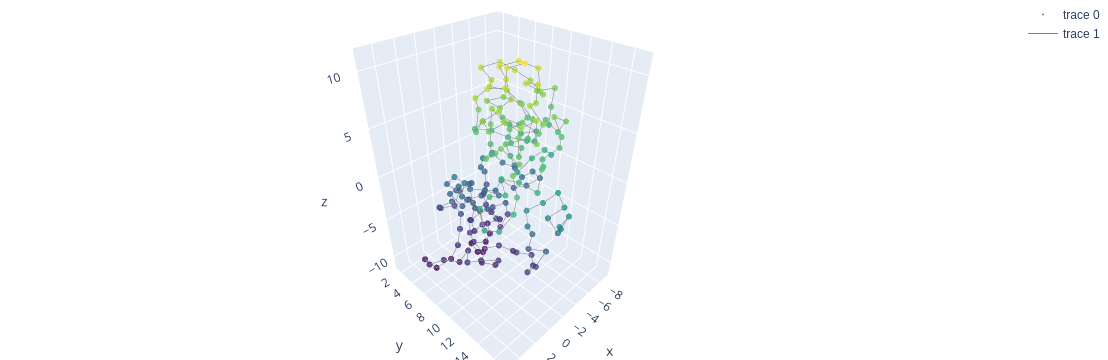

In [5]:
visualize_single_chrom(points[:196,:])

In [64]:
def visualize_whole_genome(points, resolution, diploid=False, chrom_sizes_path="../chrom_sizes/mm10.txt", p=0):
    """
    Interactive plotly visualization of a single chromosome in the form of (m,3) np.array.
    Consecutive points (rows in points array) within particular chromosomes (based on chrom_sizes_path), are assumed to be connected).
    
    If diploid==False only a single chromosome of each pair is assumed starting from chr1 and ending on chrX.
    If diploid==True the order of chromosomes is assumed to be chr1, chr1, chr2, chr2, chr3, ..., chrX, chrX.
    Parameter p signifies the percentage (integer from 0 to 100) of the points to exclude due to them lying to close to the center. 
    By default p=0, meaning that all of the points will be shown.
    """
    _, ms = get_chrom_sizes(resolution, chrom_sizes_path)
    
    if (not diploid and np.sum(ms) != points.shape[0]) or (diploid and np.sum(ms)*2 != points.shape[0]):
        error_message = f"Number of points: ({points.shape[0]}) does not match the expected number of beads ({np.sum(ms)}) for this resolution ({resolution})."
        error_message += "\nPlease check if the resolution and ploidity are correctly set."
        raise(Exception(error_message))

    k = 0
    edge_indices = []
    k_ploid = 2 if diploid else 1
    for i in range(len(ms)):
        for _ in range(k_ploid):
            for j in range(ms[i]):
                if j != ms[i]-1:
                    edge_indices.append([k, k+1])
                k += 1
    
    edge_indices = np.vstack(edge_indices)

    # Potentially excluding p percent of point lying too close to the center
    if p==0:
        is_outside = np.array([True]*points.shape[0])
    else:
        center_of_mass = np.mean(points, axis=0)
        distances = np.linalg.norm(points - center_of_mass, axis=1)
        threshold_distance = np.percentile(distances, p)
        is_outside = distances > threshold_distance

    # Prepare color palette
    palette = ['#636EFA', '#EF553B', '#00CC96', '#AB63FA', '#FFA15A', '#19D3F3', '#FF6692', '#B6E880', '#FF97FF', '#FECB52']
    point_colors = []
    color = 0
    for i in range(len(ms)):
        for _ in range(k_ploid):
            for j in range(ms[i]):
                point_colors.append(palette[color])
                if j == ms[i]-1:
                    color += 1
                    color = color%len(palette)

    
    # Construct x, y, z coordinates for lines separated by None
    edge_x, edge_y, edge_z = [], [], []
    for start_idx, end_idx in edge_indices:
        if is_outside[start_idx] or is_outside[end_idx]:
            edge_x.extend([points[start_idx, 0], points[end_idx, 0], None])
            edge_y.extend([points[start_idx, 1], points[end_idx, 1], None])
            edge_z.extend([points[start_idx, 2], points[end_idx, 2], None])
    
    # Create interactive WebGL traces
    points_plot = points[is_outside,:]
    scatter_trace = go.Scatter3d(
        x=points_plot[:, 0], y=points_plot[:, 1], z=points_plot[:, 2],
        mode='markers',
        marker=dict(size=2, color=point_colors, opacity=0.8)
    )
    
    line_trace = go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='gray', width=3),
        hoverinfo='none'
    )
    
    # 4. Render plot
    fig = go.Figure(data=[scatter_trace, line_trace])
    fig.update_layout(scene=dict(aspectmode='data'), margin=dict(l=0, r=0, b=0, t=0))
    fig.show()

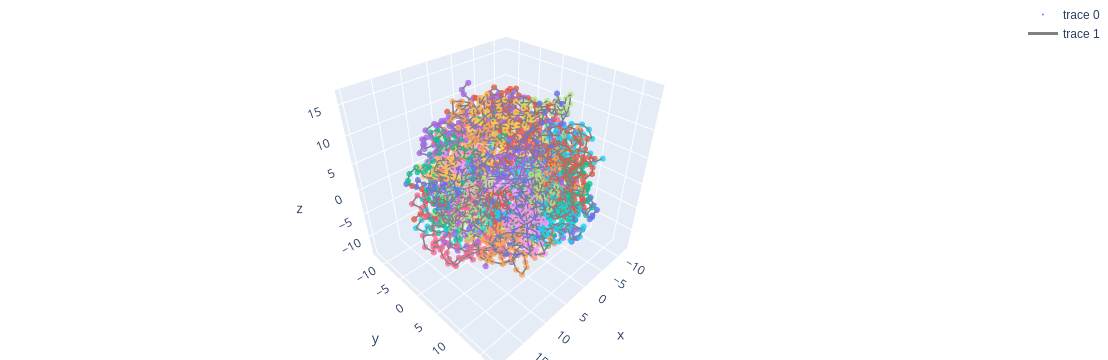

In [65]:
visualize_whole_genome(points, diploid=True, resolution=2_000_000, p=10)